# Recovering the Schottky–Klein prime function with a constrained NN (experiment)

**Goal:** For $\rho=0.3$, construct

$$P(\zeta,\rho) = (1-\zeta)\prod_{n=1}^{\infty}(1-\rho^{2n}\zeta)(1-\rho^{2n}\zeta^{-1})$$

from **functional equations** and **analyticity** (Cauchy–Riemann).

$$P(\zeta^{-1},\rho) = -\zeta^{-1} P(\zeta,\rho), \qquad P(\rho^2\zeta,\rho) = -\zeta^{-1} P(\zeta,\rho).$$

**Gauge near $\zeta\to 1$:** On $| \zeta |$ close to $1$,

$$P(\zeta,\rho) \approx (1-\zeta)\,C, \qquad C = \prod_{n=1}^{\infty}(1-\rho^{2n})^2$$

(truncated at `NMAX_REF`). We also keep **$P(1)=0$** as an explicit anchor.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

RHO = 0.3
NMAX_REF = 40
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## Reference: truncated infinite product

In [2]:
def P_ref(zeta, rho=RHO, nmax=NMAX_REF):
    zeta = np.asarray(zeta, dtype=np.complex128)
    p = 1.0 - zeta
    for n in range(1, nmax + 1):
        p *= (1.0 - rho ** (2 * n) * zeta) * (1.0 - rho ** (2 * n) / zeta)
    return p


def C_near_one(rho=RHO, nmax=NMAX_REF):
    # C = prod_{n>=1} (1 - rho^{2n})^2  (limit of P(z)/(1-z) as z -> 1)
    c = 1.0
    for n in range(1, nmax + 1):
        c *= (1.0 - rho ** (2 * n)) ** 2
    return c


C_LIMIT = C_near_one()
print(f"C = prod_n (1 - rho^{{2n}})^2 = {C_LIMIT:.12f}")

# Check P_ref(z) ~ (1-z)*C for z near 1
for r in [0.92, 0.96, 0.99]:
    z = r + 0.0j
    ratio = P_ref(z) / (1.0 - z)
    print(f"|z|={r}: P/(1-z) = {ratio:.8f},  |ratio - C| = {abs(ratio - C_LIMIT):.2e}")

for _ in range(5):
    th = np.random.rand() * 2 * np.pi
    r = np.random.uniform(RHO + 0.05, 0.95)
    z = r * np.exp(1j * th)
    e1 = P_ref(1 / z) + P_ref(z) / z
    e2 = P_ref(RHO**2 * z) + P_ref(z) / z
    print(f"|FE1|={abs(e1):.2e}  |FE2|={abs(e2):.2e}")


C = prod_n (1 - rho^{2n})^2 = 0.813434347569
|z|=0.92: P/(1-z) = 0.81276826+0.00000000j,  |ratio - C| = 6.66e-04
|z|=0.96: P/(1-z) = 0.81327476+0.00000000j,  |ratio - C| = 1.60e-04
|z|=0.99: P/(1-z) = 0.81342468+0.00000000j,  |ratio - C| = 9.67e-06
|FE1|=4.58e-16  |FE2|=4.58e-16
|FE1|=1.33e-15  |FE2|=9.93e-16
|FE1|=2.36e-16  |FE2|=1.39e-17
|FE1|=4.97e-16  |FE2|=3.33e-16
|FE1|=2.48e-15  |FE2|=2.48e-15


## Complex NN: $\zeta=x+iy \mapsto P=u+iv$

The network has **two outputs (real and imaginary parts)**; complex arithmetic is done explicitly.

In [ ]:
def c_inv(zr, zi):
    d = zr * zr + zi * zi + 1e-12
    return zr / d, -zi / d


def c_mul(ar, ai, br, bi):
    return ar * br - ai * bi, ar * bi + ai * br


def c_scale(ar, ai, s):
    return ar * s, ai * s


class PrimeNet(nn.Module):
    def __init__(self, width=64, depth=5):
        super().__init__()
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, zr, zi):
        x = torch.stack([zr, zi], dim=-1)
        out = self.net(x)
        return out[..., 0], out[..., 1]


def grad_scalar(y, x):
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True
    )[0]


def sample_annulus(n, rho=RHO, r_min=None, r_max=0.95):
    if r_min is None:
        r_min = rho + 0.05
        #r_min = 1e-3
    th = torch.rand(n, device=device) * (2 * np.pi)
    r = r_min + (r_max - r_min) * torch.rand(n, device=device)
    zr = r * torch.cos(th)
    zi = r * torch.sin(th)
    return zr, zi


def sample_near_one(n, r_min=0.99, r_max=0.999):
    # |zeta| close to 1 (outer boundary of annulus)
    th = torch.rand(n, device=device) * (2 * np.pi)
    r = r_min + (r_max - r_min) * torch.rand(n, device=device)
    zr = r * torch.cos(th)
    zi = r * torch.sin(th)
    return zr, zi


## Loss function

1. **FE1:** $P(1/\zeta) + \zeta^{-1}P(\zeta)=0$  
2. **FE2:** $P(\rho^2\zeta) + \zeta^{-1}P(\zeta)=0$  
3. **CR:** Cauchy–Riemann  
4. **Near $\zeta\to 1$:** $P(\zeta) \approx (1-\zeta)\,C$ with $C=\prod_{n=1}^{\infty}(1-\rho^{2n})^2$ (`C_LIMIT`; sampled on $| \zeta |\approx 1$)  
5. **Anchor at $\zeta=1$:** $P(1)=0$

No global data fit to $P_{\mathrm{ref}}$ on the full annulus.


In [6]:
def losses(
    model,
    zr,
    zi,
    w_fe=1.0,
    w_cr=0.1,
    w_near1=2.0,
    w_anchor_one=10.0,
    n_near1=128,
):
    zr = zr.clone().requires_grad_(True)
    zi = zi.clone().requires_grad_(True)

    ur, ui = model(zr, zi)

    zinv_r, zinv_i = c_inv(zr, zi)
    uinv_r, uinv_i = model(zinv_r, zinv_i)
    t1r, t1i = c_mul(ur, ui, zinv_r, zinv_i)
    res1r = uinv_r + t1r
    res1i = uinv_i + t1i
    L_fe1 = torch.mean(res1r**2 + res1i**2)

    z2r, z2i = c_scale(zr, zi, RHO**2)
    u2r, u2i = model(z2r, z2i)
    res2r = u2r + t1r
    res2i = u2i + t1i
    L_fe2 = torch.mean(res2r**2 + res2i**2)

    u_x = grad_scalar(ur, zr)
    u_y = grad_scalar(ur, zi)
    v_x = grad_scalar(ui, zr)
    v_y = grad_scalar(ui, zi)
    L_cr = torch.mean((u_x - v_y) ** 2 + (u_y + v_x) ** 2)

    # P(z) ~ (1 - z) * C_LIMIT  for z near 1
    zr1, zi1 = sample_near_one(n_near1)
    ur1, ui1 = model(zr1, zi1)
    c = torch.tensor(C_LIMIT, device=device, dtype=zr.dtype)
    tr = c * (1.0 - zr1)
    ti = -c * zi1
    L_near1 = torch.mean((ur1 - tr) ** 2 + (ui1 - ti) ** 2)

    z1r = torch.ones(32, device=device, dtype=zr.dtype)
    z1i = torch.zeros(32, device=device, dtype=zr.dtype)
    u1r, u1i = model(z1r, z1i)
    L_one = torch.mean(u1r**2 + u1i**2)

    L = w_fe * (L_fe1 + L_fe2) + w_cr * L_cr + w_near1 * L_near1 + w_anchor_one * L_one
    return L, dict(
        fe1=L_fe1.item(),
        fe2=L_fe2.item(),
        cr=L_cr.item(),
        near1=L_near1.item(),
        one=L_one.item(),
    )


## Training

In [7]:
torch.manual_seed(0)
model = PrimeNet(width=80, depth=6).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
N = 512
hist = []
for epoch in range(8000):
    opt.zero_grad()
    zr, zi = sample_annulus(N)
    L, parts = losses(
        model,
        zr,
        zi,
        w_fe=1.0,
        w_cr=0.2,
        w_near1=2.0,
        w_anchor_one=20.0,
    )
    L.backward()
    opt.step()
    hist.append(L.item())
    if (epoch + 1) % 2000 == 0:
        print(f"epoch {epoch+1}  L={L.item():.3e}  {parts}")


epoch 2000  L=2.203e+00  {'fe1': 0.004384917672723532, 'fe2': 0.009206758812069893, 'cr': 0.0017108622705563903, 'near1': 1.0893237590789795, 'one': 0.0005131731741130352}
epoch 4000  L=2.012e+00  {'fe1': 0.08403748273849487, 'fe2': 0.10680194199085236, 'cr': 0.021620625630021095, 'near1': 0.8789581060409546, 'one': 0.002938007703050971}
epoch 6000  L=1.230e+01  {'fe1': 5.835756778717041, 'fe2': 5.953805923461914, 'cr': 0.09198424965143204, 'near1': 0.1418893188238144, 'one': 0.01030808687210083}
epoch 8000  L=1.503e+00  {'fe1': 0.13224302232265472, 'fe2': 0.1679336130619049, 'cr': 0.025069978088140488, 'near1': 0.5610703825950623, 'one': 0.003786651184782386}


## Visualization: $|P|$ and loss on the annulus (donut plot in the $\zeta$-plane)

relative L2 vs P_ref (diagnostic): 0.8247046217503484
mean |FE1| on annulus: 0.18436389
mean |FE2| on annulus: 0.31324697
mean |(1-z)C - P_NN| on annulus: 0.72121114


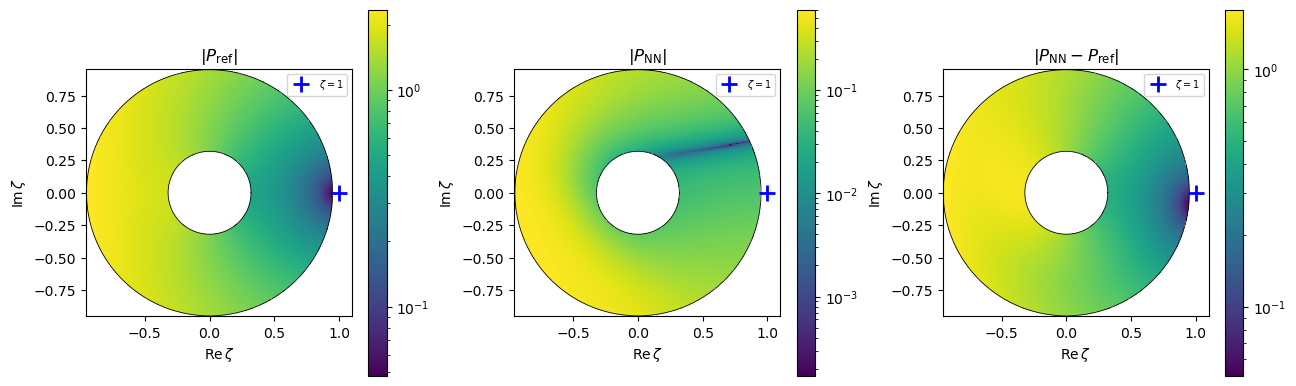

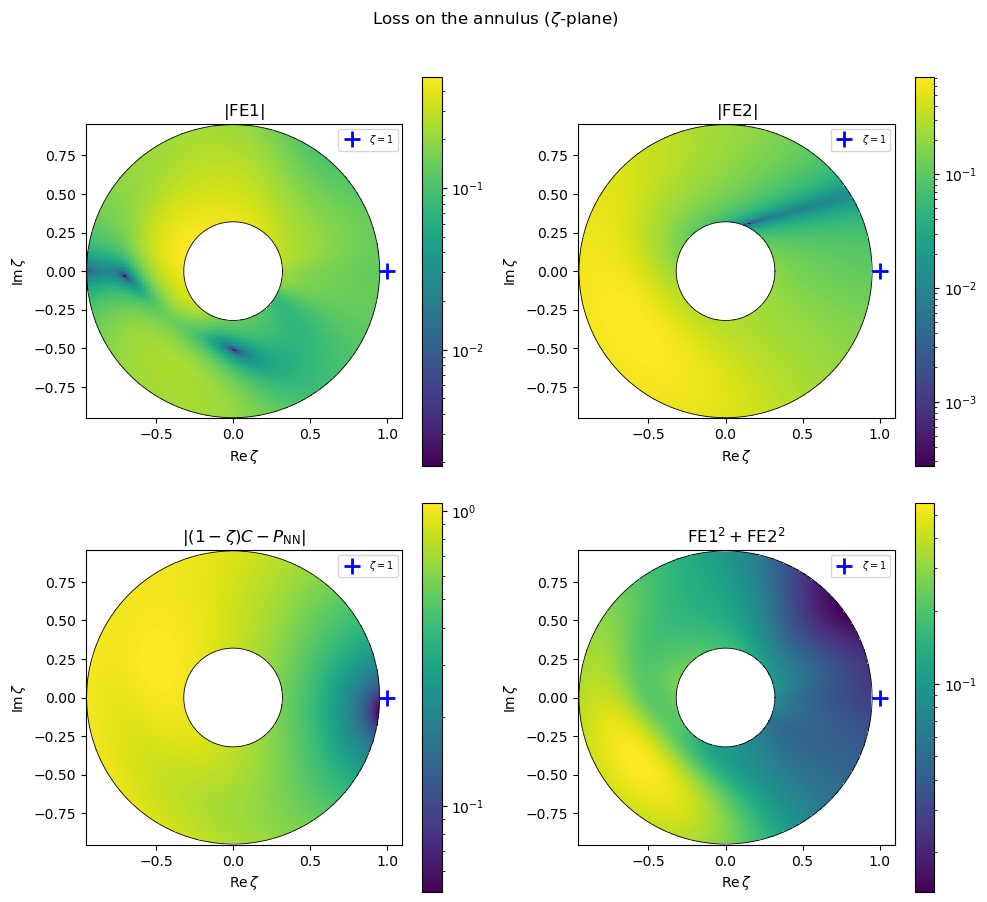

In [8]:
from matplotlib.colors import LogNorm

r_in, r_out = RHO + 0.02, 0.95
n = 220
x = np.linspace(-r_out, r_out, n)
y = np.linspace(-r_out, r_out, n)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y
mask = (np.abs(Z) >= r_in) & (np.abs(Z) <= r_out)

Pref = P_ref(Z)
shape = Z.shape

zr = torch.tensor(Z.real, dtype=torch.float32, device=device).ravel()
zi = torch.tensor(Z.imag, dtype=torch.float32, device=device).ravel()
with torch.no_grad():
    ur, ui = model(zr, zi)
    zinv_r, zinv_i = c_inv(zr, zi)
    uinv_r, uinv_i = model(zinv_r, zinv_i)
    t1r, t1i = c_mul(ur, ui, zinv_r, zinv_i)
    fe1_mag = torch.sqrt((uinv_r + t1r) ** 2 + (uinv_i + t1i) ** 2)
    z2r, z2i = c_scale(zr, zi, RHO**2)
    u2r, u2i = model(z2r, z2i)
    fe2_mag = torch.sqrt((u2r + t1r) ** 2 + (u2i + t1i) ** 2)
    c = torch.tensor(C_LIMIT, device=device, dtype=zr.dtype)
    tr = c * (1.0 - zr)
    ti = -c * zi
    near1_mag = torch.sqrt((ur - tr) ** 2 + (ui - ti) ** 2)
    loss_pt = (fe1_mag ** 2 + fe2_mag ** 2).cpu().numpy().reshape(shape)

Pnn = (ur + 1j * ui).cpu().numpy().reshape(shape)
fe1_map = fe1_mag.cpu().numpy().reshape(shape)
fe2_map = fe2_mag.cpu().numpy().reshape(shape)
near1_map = near1_mag.cpu().numpy().reshape(shape)

m = mask
rel_err = np.linalg.norm((Pnn - Pref)[m]) / (np.linalg.norm(Pref[m]) + 1e-12)
print("relative L2 vs P_ref (diagnostic):", rel_err)
print("mean |FE1| on annulus:", fe1_map[m].mean())
print("mean |FE2| on annulus:", fe2_map[m].mean())
print("mean |(1-z)C - P_NN| on annulus:", near1_map[m].mean())

th_circ = np.linspace(0, 2 * np.pi, 256)


def _annulus_plot(ax, field, title, log_scale=True):
    data = np.ma.masked_where(~mask, field)
    if log_scale:
        vals = data.compressed()
        vmin = max(vals.min(), 1e-12) if vals.size else 1e-12
        vmax = vals.max() if vals.size else 1.0
        im = ax.pcolormesh(X, Y, data, shading="auto", norm=LogNorm(vmin=vmin, vmax=vmax))
    else:
        im = ax.pcolormesh(X, Y, data, shading="auto")
    ax.plot(r_in * np.cos(th_circ), r_in * np.sin(th_circ), "k-", lw=0.6)
    ax.plot(r_out * np.cos(th_circ), r_out * np.sin(th_circ), "k-", lw=0.6)
    ax.plot(1.0, 0.0, "b+", ms=12, mew=2, label=r"$\zeta=1$")
    plt.colorbar(im, ax=ax)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel(r"$\mathrm{Re}\,\zeta$")
    ax.set_ylabel(r"$\mathrm{Im}\,\zeta$")
    ax.legend(loc="upper right", fontsize=7)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
_annulus_plot(ax[0], np.abs(Pref), r"$|P_{\mathrm{ref}}|$")
_annulus_plot(ax[1], np.abs(Pnn), r"$|P_{\mathrm{NN}}|$")
_annulus_plot(ax[2], np.abs(Pnn - Pref), r"$|P_{\mathrm{NN}} - P_{\mathrm{ref}}|$")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(10, 9))
_annulus_plot(ax[0, 0], fe1_map, r"$|\mathrm{FE1}|$")
_annulus_plot(ax[0, 1], fe2_map, r"$|\mathrm{FE2}|$")
_annulus_plot(ax[1, 0], near1_map, r"$|(1-\zeta)C - P_{\mathrm{NN}}|$")
_annulus_plot(ax[1, 1], loss_pt, r"$\mathrm{FE1}^2+\mathrm{FE2}^2$")
plt.suptitle(r"Loss on the annulus ($\zeta$-plane)", y=1.02)
plt.tight_layout()
plt.show()


## Discussion and next steps

- **Near $\zeta=1$:** $P(\zeta)\approx(1-\zeta)\prod_n(1-\rho^{2n})^2$ fixes the leading behavior at the unit circle.
- **$P(1)=0$** is consistent with the factor $(1-\zeta)$.
- Structured ansatz (truncated product) may improve identifiability.
